# Robustness

The MELON sensitivity and ablation panels are traced to the archived evaluation CSV files. Their scores are read directly; no parameter sweep is run.

Read the stored outputs below in order. These cells load and plot archived results; they do not preprocess inputs, train models, cluster spots, or fit a new UMAP/t-SNE.

Data: `Published_Data_non_NASH/01_Mouse_E15_5/`. The sharedoc download link will be added after the archive is uploaded.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "01_Mouse_E15_5"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


## 1. Read the saved sensitivity scores

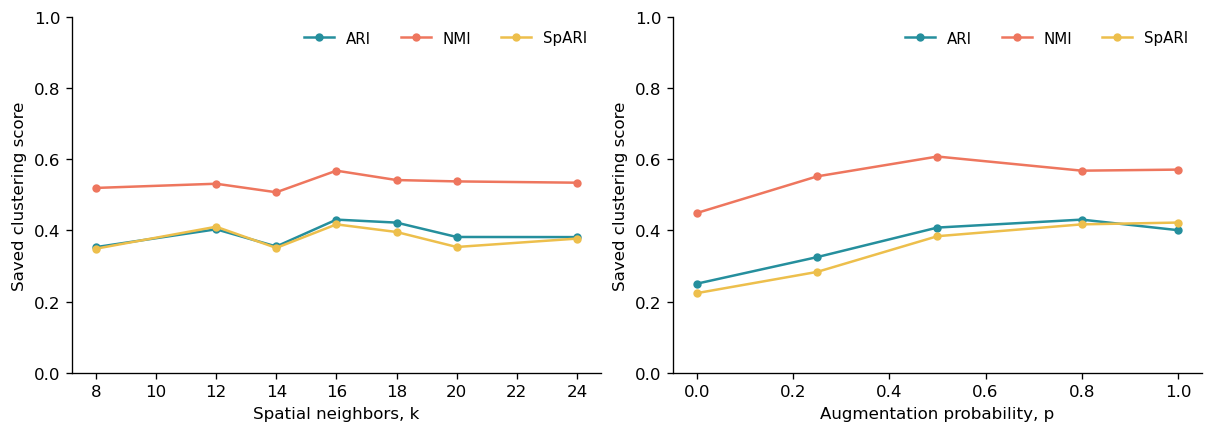

In [2]:
RESULTS = DATA / "05_Fig5_robustness"
neighbors = pd.read_csv(RESULTS / "neighbor_k_local_report_metrics.csv")
augmentation = pd.read_csv(RESULTS / "augment_p_report_metrics.csv")
show(sensitivity_panels(neighbors, augmentation))

## 2. Inspect the archived ablation sweep

The input contains an existing sweep across six cluster counts. Bars are medians and error bars are the 25th and 75th percentiles. The saved full-model median ARI is 0.383.

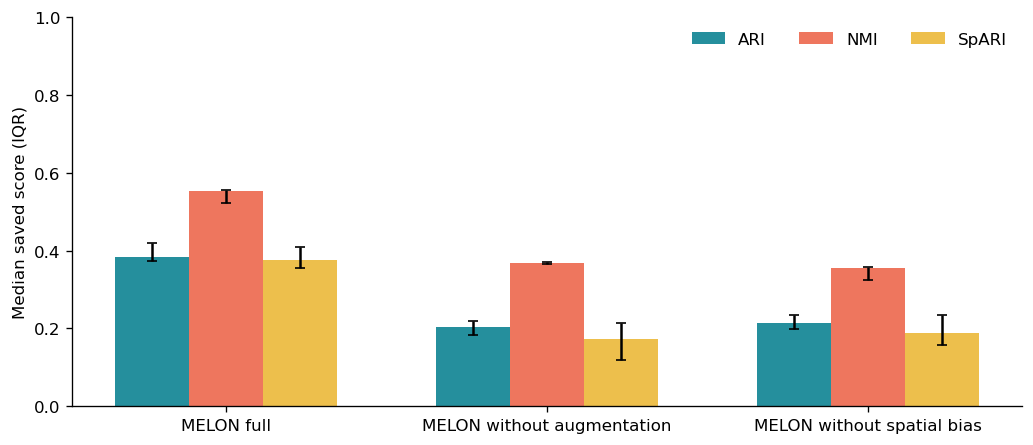

In [3]:
ablation = pd.read_csv(RESULTS / "ablation_multik_metrics_E15.csv")
show(ablation_panels(ablation))